# Бизнес-кейс №3

Необходимо предсказать, согласится ли клиент открыть срочный вклад по итогам телемаркетинговой кампании, используя демографические признаки, историю контактов и экономические индикаторы

***Задача бинарной классификации***

## Цели и задачи:
1. Оценить качество данных:
    - пропуски данных
    - дубликаты
    - выбросы
2. Очистка/исправление аномалий
3. Ананлиз распределения признаков
4. Исследование взаимосвязи между признаками (корреляция)

## Импорты и настройки

In [19]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Загрузка данных
from ucimlrepo import fetch_ucirepo 

## 1. Превью DF

In [20]:
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
df = pd.concat([X, y], axis=1)
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


### 1.1 Описание столбцов датасета

In [21]:
pd.set_option('display.max_colwidth', None)
print(list(df.columns))
display(bank_marketing.variables)

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,None,None,no
1,job,Feature,Categorical,Occupation,"type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')",None,no
2,marital,Feature,Categorical,Marital Status,"marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)",None,no
3,education,Feature,Categorical,Education Level,"(categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')",None,no
4,default,Feature,Binary,None,has credit in default?,None,no
5,balance,Feature,Integer,None,average yearly balance,euros,no
6,housing,Feature,Binary,None,has housing loan?,None,no
7,loan,Feature,Binary,None,has personal loan?,None,no
8,contact,Feature,Categorical,None,"contact communication type (categorical: 'cellular','telephone')",None,yes
9,day_of_week,Feature,Date,None,last contact day of the week,None,no


### Выводы
Признаки в наборе делятся на три логические категории:
- **Данные о клиенте.** Возраст (age), род занятий (job), семейное положение (marital), образование (education), наличие дефолта (default), среднегодовой баланс в евро (balance), наличие ипотеки (housing) и потребительского кредита (loan).

- **Детали последнего контакта.** Тип связи (contact — мобильный или городской), день месяца (day), месяц (month) и длительность звонка в секундах (duration).

- **История маркетинговых кампаний.** Количество контактов с клиентом в текущей кампании (campaign), число дней с прошлого звонка (pdays), количество прошлых контактов (previous) и результат предыдущей кампании (poutcome).

## 2. Первичный осмотр данных 

### 2.1 Автогенернация на сырых данных

In [22]:
!pip3 install ydata-profiling
from ydata_profiling import ProfileReport

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [8]:
df_for_report = df.copy()

cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome', 'y']
for col in cat_cols:
    if col in df_for_report.columns:
        df_for_report[col] = df_for_report[col].astype('category')

profile = ProfileReport(
    df_for_report,
    title="Data Profiling Report: Bank Marketing Dataset",
    explorative=True,
    correlations={
        "pearson": {"calculate": False},
        "spearman": {"calculate": False},
        "kendall": {"calculate": False},
        "cramers": {"calculate": False},
        "phi_k": {"calculate": True}  
    }
)


profile.to_file("bank_marketing.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 17/17 [00:00<00:00, 3732.95it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 2.2 Первый взгляд на данные

In [23]:
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
5,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
6,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
8,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
9,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no


In [24]:
df.sample(30, random_state=50)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
33955,32,services,married,secondary,no,386,no,no,cellular,30,apr,222,1,-1,0,NaN,no
34904,26,management,single,tertiary,no,1494,yes,no,cellular,6,may,477,2,-1,0,NaN,no
5547,38,blue-collar,married,secondary,no,1102,yes,no,NaN,23,may,159,3,-1,0,NaN,no
15633,41,technician,married,secondary,no,525,yes,no,cellular,21,jul,108,1,-1,0,NaN,no
41402,19,student,single,secondary,no,4,no,no,cellular,3,sep,114,1,-1,0,NaN,no
20608,43,management,single,tertiary,no,1627,no,no,cellular,12,aug,105,4,-1,0,NaN,no
38208,24,admin.,married,secondary,no,-94,yes,no,cellular,15,may,217,1,-1,0,NaN,no
30621,36,unemployed,married,primary,no,0,no,no,cellular,6,feb,409,1,-1,0,NaN,no
8247,44,blue-collar,divorced,primary,yes,-119,yes,no,NaN,2,jun,132,5,-1,0,NaN,no
10630,50,blue-collar,married,secondary,no,887,no,no,NaN,16,jun,287,1,-1,0,NaN,no


#### Что бросатеся в глаза в результате беглого осмотра срезов и требует исследования:
1. pdays = -1
2. poutcome = NaN
3. previous = 0
4. Нечастые yes в tartget


### 2.3 Технический паспорт данных

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | int64(7), object(10) | OK, но можно оптимизировать |
| **Пропуски** | Есть в `job`, `education`, `contact`, `poutcome` | Нужно исследовать |


#### 2.3.1 Оптимизация памяти

In [26]:
# Анализ типов данных
df.dtypes.value_counts()

object    10
int64      7
Name: count, dtype: int64

In [27]:
# Замер памяти до оптимизации
memory_before = df.memory_usage(deep=True).sum() / 1024**2

# Числовые типы
# выбрать атоматически
int_cols = df.select_dtypes(include=['int64']).columns

for col in int_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')

# Категориальные типы (уникальность < 20%)
cat_candidates = df.select_dtypes(include=['object']).columns
for col in cat_candidates:
    if col in df.columns:
        unique_ratio = df[col].nunique() / len(df)
        if unique_ratio < 0.2:
            df[col] = df[col].astype('category')
            print(f" {col} → category (уникальность: {unique_ratio:.1%})")

# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2

# Вывод
print(f"\n💾 Память до: {memory_before:.2f} MB")
print(f"\n💾 Память после: {memory_after:.2f} MB")
print(f"\n📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")

 job → category (уникальность: 0.0%)
 marital → category (уникальность: 0.0%)
 education → category (уникальность: 0.0%)
 default → category (уникальность: 0.0%)
 housing → category (уникальность: 0.0%)
 loan → category (уникальность: 0.0%)
 contact → category (уникальность: 0.0%)
 month → category (уникальность: 0.0%)
 poutcome → category (уникальность: 0.0%)
 y → category (уникальность: 0.0%)

💾 Память до: 27.61 MB

💾 Память после: 1.00 MB

📉 Экономия: 96.4%


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   age          45211 non-null  int8    
 1   job          44923 non-null  category
 2   marital      45211 non-null  category
 3   education    43354 non-null  category
 4   default      45211 non-null  category
 5   balance      45211 non-null  int32   
 6   housing      45211 non-null  category
 7   loan         45211 non-null  category
 8   contact      32191 non-null  category
 9   day_of_week  45211 non-null  int8    
 10  month        45211 non-null  category
 11  duration     45211 non-null  int16   
 12  campaign     45211 non-null  int8    
 13  pdays        45211 non-null  int16   
 14  previous     45211 non-null  int16   
 15  poutcome     8252 non-null   category
 16  y            45211 non-null  category
dtypes: category(10), int16(3), int32(1), int8(3)
memory usage: 1017.4 KB


**Выявлена ошибка именования** 
day_of_week - явно обозначает день месяца


In [29]:
df = df.rename(columns={'day_of_week': 'day_of_month'})

### 2.4 Статистическая сводка

In [30]:
# Числовые переменные
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_month,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [31]:
# Категориальные переменные
df.describe(include=['category']).T

,count,unique,top,freq
job,44923,11,blue-collar,9732
marital,45211,3,married,27214
education,43354,3,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,32191,2,cellular,29285
month,45211,12,may,13766
poutcome,8252,3,failure,4901
y,45211,2,no,39922


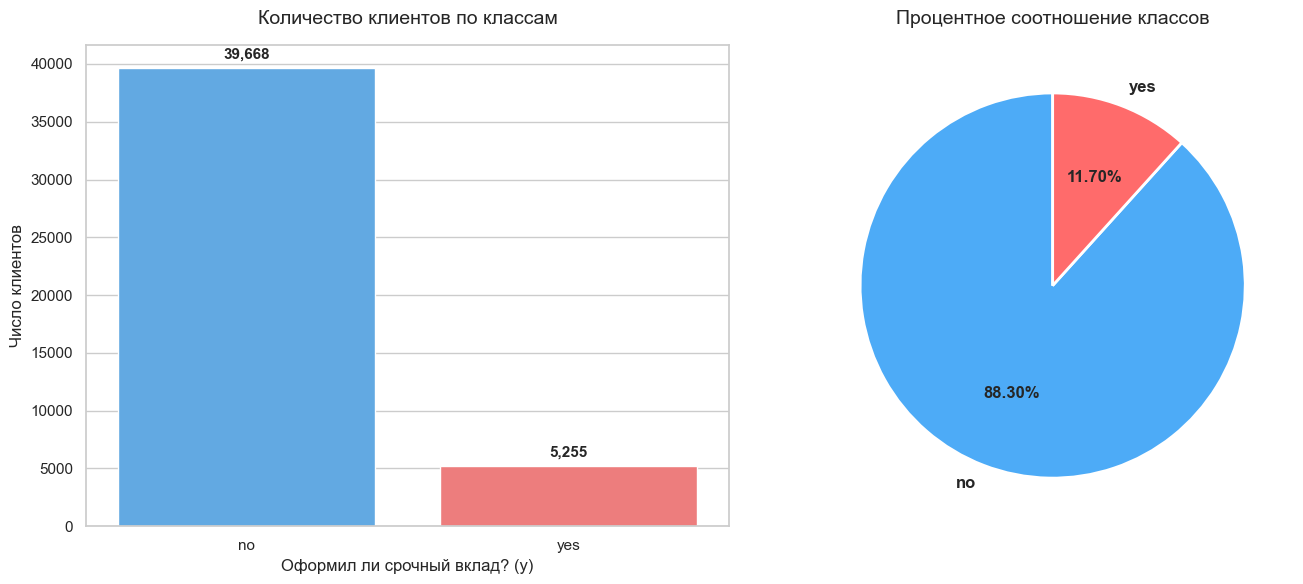

Точные цифры дисбаланса классов:
  Класс 'no': 39668 строк (88.30%)
  Класс 'yes': 5255 строк (11.70%)


In [46]:
%matplotlib inline
target_counts = df['y'].astype(str).value_counts()
target_pct = df['y'].astype(str).value_counts(normalize=True) * 100

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=target_counts.index, y=target_counts.values, ax=axes[0], palette=['#4dabf7', '#ff6b6b'], hue=target_counts.index, legend=False)
axes[0].set_title('Количество клиентов по классам', fontsize=14, pad=15)
axes[0].set_xlabel('Оформил ли срочный вклад? (y)', fontsize=12)
axes[0].set_ylabel('Число клиентов', fontsize=12)

for i, val in enumerate(target_counts.values):
    axes[0].text(i, val + 500, f"{val:,}", ha='center', va='bottom', fontsize=11, weight='bold')

axes[1].pie(
    target_pct.values, 
    labels=target_pct.index, 
    autopct='%1.2f%%', 
    startangle=90, 
    colors=['#4dabf7', '#ff6b6b'],
    textprops={'fontsize': 12, 'weight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[1].set_title('Процентное соотношение классов', fontsize=14, pad=15)

plt.tight_layout()
plt.show()

print("Точные цифры дисбаланса классов:")
for cls, cnt, pct in zip(target_counts.index, target_counts.values, target_pct.values):
    print(f"  Класс '{cls}': {cnt} строк ({pct:.2f}%)")


## 3. Качество данных

### 3.1 Анализ пропусков

In [35]:
# Количество пропусков
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64



--- Признак: poutcome ---
          Количество  Конверсия (%)
poutcome                           
success         1511          64.73
other           1840          16.68
failure         4901          12.61
unknown        36959           9.16

--- Признак: contact ---
           Количество  Конверсия (%)
contact                             
cellular        29285          14.92
telephone        2906          13.42
unknown         13020           4.07

--- Признак: education ---
           Количество  Конверсия (%)
education                           
tertiary        13301          15.01
unknown          1857          13.57
secondary       23202          10.56
primary          6851           8.63

--- Признак: job ---
               Количество  Конверсия (%)
job                                     
student               938          28.68
retired              2264          22.79
unemployed           1303          15.50
management           9458          13.76
admin.               5171   

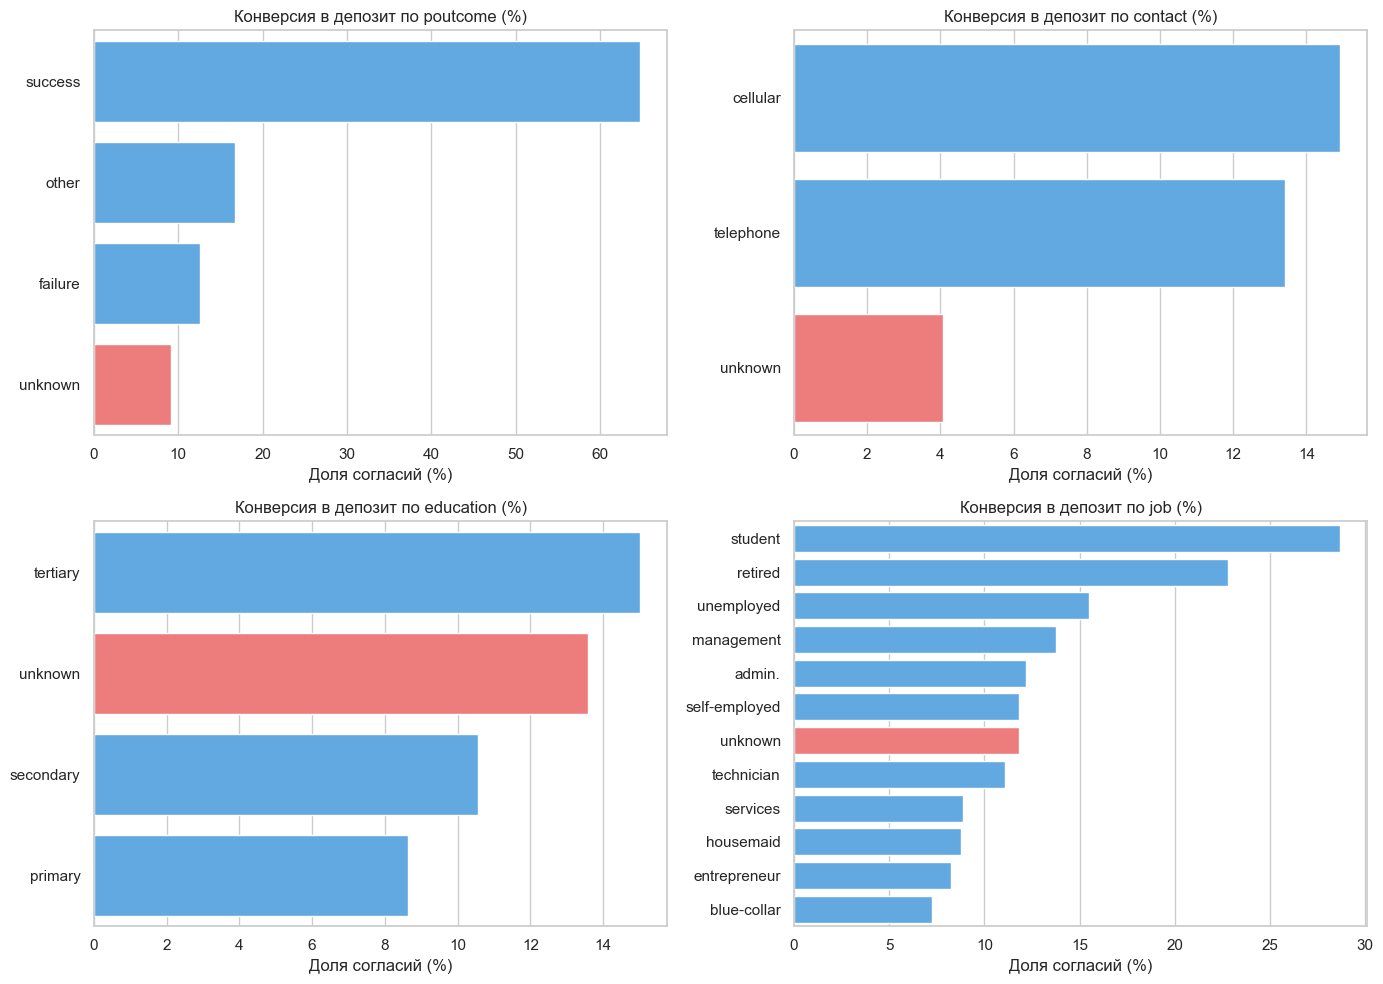

In [36]:
cols_with_na = ['poutcome', 'contact', 'education', 'job']

target_num = df['y'].astype(str).isin(['yes', '1']).astype(int)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cols_with_na):
    temp_series = df[col].astype(str).replace('nan', 'unknown').fillna('unknown')
    
    stats = pd.DataFrame({
        'Количество': temp_series.value_counts(),
        'Конверсия (%)': (target_num.groupby(temp_series).mean() * 100).round(2)
    }).sort_values(by='Конверсия (%)', ascending=False)
    
    print(f"\n--- Признак: {col} ---")
    print(stats)

    colors = ['#ff6b6b' if idx == 'unknown' else '#4dabf7' for idx in stats.index]
    sns.barplot(x=stats['Конверсия (%)'], y=stats.index, ax=axes[i], palette=colors, hue=stats.index, legend=False)
    axes[i].set_title(f'Конверсия в депозит по {col} (%)')
    axes[i].set_xlabel('Доля согласий (%)')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

#### Вывод
1. Строк с пропусками в job всего 288 (это менее 0.64 % от всех 45 211 записей), а их конверсия (11.81 %) почти не отличается от средней по всей выборке (11.70 %) - удаляем

In [37]:
df = df.dropna(subset=['job']).reset_index(drop=True)

### 3.2 Анализ выбросов

 Признак   Min  50% (Медиана)    95%     99%    Max  Верхняя граница IQR  Выбросов по IQR (%)
 balance -8019          447.0 5763.0 13159.1 102127               3444.5                10.49
     age    18           39.0   59.0    71.0     95                 70.5                 1.07
campaign     1            2.0    8.0    16.0     63                  6.0                 6.75
   pdays    -1           -1.0  318.0   370.0    871                 -1.0                18.31
previous     0            0.0    3.0     9.0    275                  0.0                18.31


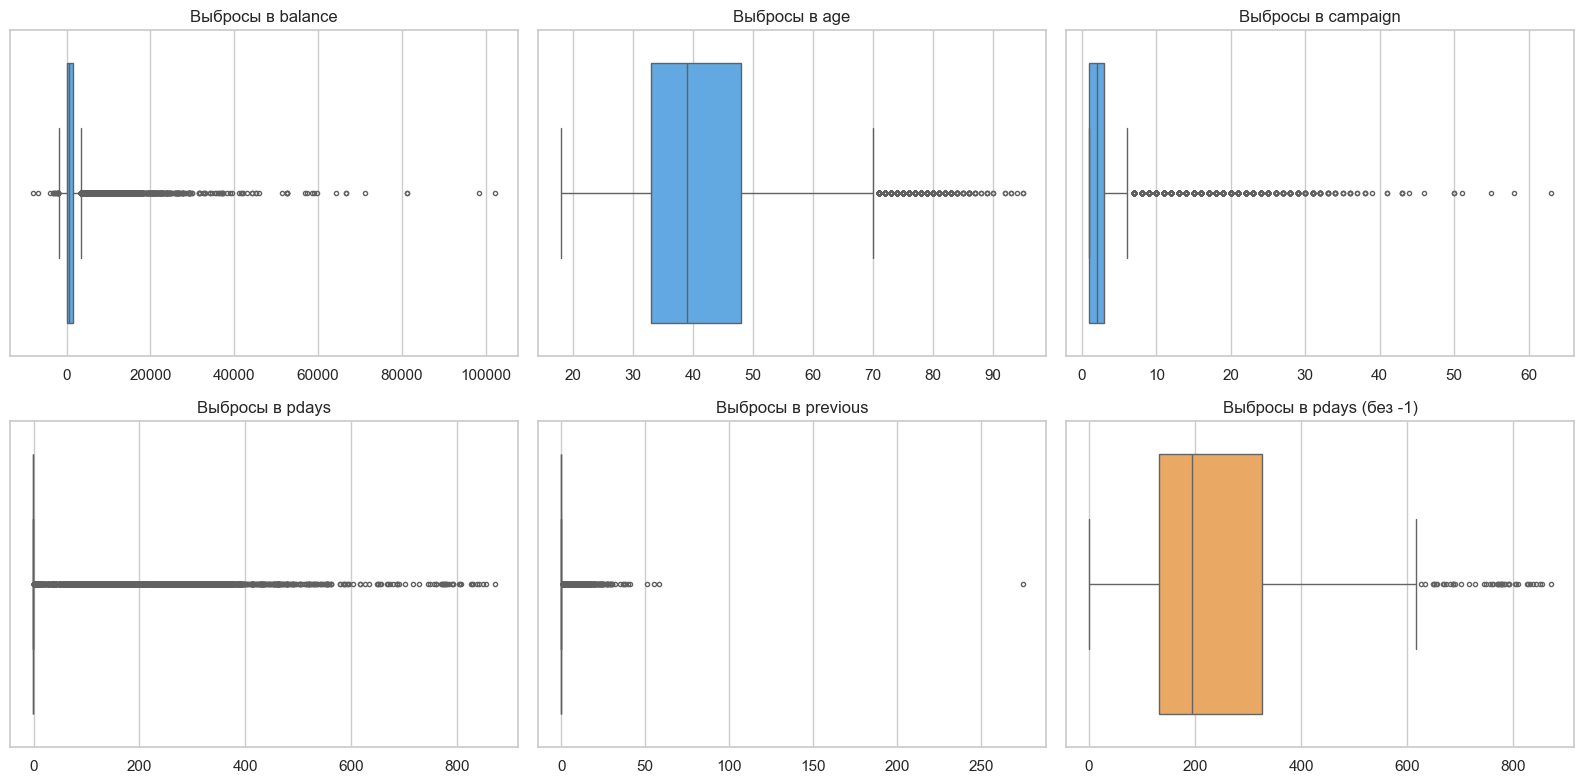

In [45]:
num_cols = ['balance', 'age', 'campaign', 'pdays', 'previous']

# 1. Сводная таблица квантилей и границ IQR
outlier_summary = []

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers_cnt = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    
    outlier_summary.append({
        'Признак': col,
        'Min': df[col].min(),
        '50% (Медиана)': df[col].median(),
        '95%': round(df[col].quantile(0.95), 1),
        '99%': round(df[col].quantile(0.99), 1),
        'Max': df[col].max(),
        'Верхняя граница IQR': round(upper_bound, 1),
        'Выбросов по IQR (%)': round(outliers_cnt / len(df) * 100, 2)
    })

summary_df = pd.DataFrame(outlier_summary)
print(summary_df.to_string(index=False))

# 2. Визуализация распределений и выбросов (Boxplot)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='#4dabf7', fliersize=3)
    axes[i].set_title(f'Выбросы в {col}')
    axes[i].set_xlabel('')

# Отдельно посмотрим pdays без значения -1
sns.boxplot(x=df.loc[df['pdays'] != -1, 'pdays'], ax=axes[5], color='#ffa94d', fliersize=3)
axes[5].set_title('Выбросы в pdays (без -1)')
axes[5].set_xlabel('')

plt.tight_layout()
plt.show()


#### Выводы
| Признак | Выбросы | Интерпретация |
|---------|---------|---------------|
| **balance** | Много > 10k | богатые клиенты (есть средства открыть вклад) |
| **age** | Немного | Пенсионеры (пенсионеры чаще имеют накопления) |
| **campaign** | 1% > 16 | избавиться от хвоста |
| **pdays** | много -1 | проверим связь с  previous скорее всего тех признак|
| **previous** | много 0 | проверим связь pdays |

### 3.3 Проверка аномалий

In [39]:
display(df[(df['pdays'] == -1) & (df['previous'] == 0)].head(15))
print(f"\nСтрок с pdays = -1: {len(df[df['pdays'] == -1])}")
print(f"\nСтрок с previous = 0 дней: {len(df[df['previous'] == 0])}")
print(f"\nСтрок обладающих одновременно признаками: {len(df[(df['pdays'] == -1) & (df['previous'] == 0)])}")

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
5,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
6,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
7,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
8,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no
9,41,admin.,divorced,secondary,no,270,yes,no,NaN,5,may,222,1,-1,0,NaN,no



Строк с pdays = -1: 36699

Строк с previous = 0 дней: 36699

Строк обладающих одновременно признаками: 36699


### Вывод
Это новые клиенты, по которым нет данных о прошлых компаниях.

In [40]:
df[(df['pdays'] != -1) & (df['previous'] != 0) & (df['poutcome'].isna()) ]


,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
40415,61,retired,married,tertiary,no,3140,yes,yes,cellular,6,aug,975,4,98,1,NaN,yes
41568,39,management,married,tertiary,no,184,no,no,cellular,15,oct,206,1,168,5,NaN,no
41783,26,admin.,single,secondary,no,338,no,no,cellular,29,oct,209,1,188,2,NaN,yes
43704,30,technician,single,secondary,no,254,yes,yes,cellular,24,jun,167,3,416,2,NaN,no
44735,37,management,married,secondary,no,209,no,no,cellular,14,oct,183,3,528,7,NaN,no


In [41]:
df[df['poutcome'] == 'other'].sample(30, random_state=50)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
33429,29,blue-collar,married,secondary,no,457,yes,no,cellular,20,apr,72,3,341,1,other,no
27307,44,blue-collar,married,primary,no,0,yes,yes,cellular,21,nov,32,2,116,3,other,no
44670,51,management,married,tertiary,no,5108,yes,no,cellular,8,oct,272,1,102,8,other,no
44294,29,management,single,tertiary,no,1673,no,no,cellular,16,aug,200,2,159,3,other,no
41417,41,admin.,married,secondary,no,158,yes,no,cellular,1,oct,250,2,120,4,other,no
43295,37,admin.,married,secondary,no,55,yes,yes,cellular,27,apr,99,1,329,4,other,no
33346,37,technician,single,secondary,no,442,yes,no,cellular,20,apr,51,4,349,1,other,no
44066,47,management,divorced,tertiary,no,-130,yes,no,cellular,30,jul,221,4,431,5,other,no
41187,26,management,single,tertiary,no,9447,no,no,cellular,4,sep,113,1,100,2,other,no
33222,34,technician,divorced,secondary,no,0,yes,yes,cellular,20,apr,110,3,269,2,other,no


### Вывод
Выявлены некорреткно внесенные данные у 5 повторных клиентов
 - можно удалить
 - или присвоить значение other (так как выглядит это как человеческий фактор лучше этот вариант)

In [42]:
mask_returning_na = (df['pdays'] != -1) & (df['poutcome'].isna())
df.loc[mask_returning_na, 'poutcome'] = 'other'

In [43]:
df[df['job'].isna()]

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y


### Выводы

1. В общей выборке признаки pdays, previous и poutcome будут иметь низкую конверсию, добавим бинарный признак новый или старый клиент
2. Для новых клиентов pdays, previous и poutcome не имеют смысла удалим признаки


In [48]:
df[df['pdays'] == -1]

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44915,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,NaN,yes
44917,25,technician,single,secondary,no,505,no,yes,cellular,17,nov,386,2,-1,0,NaN,yes
44918,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
44919,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes


## 4. Мультиколлинеарность

interval columns not set, guessing: ['age', 'balance', 'day_of_month', 'duration', 'campaign', 'pdays', 'previous']


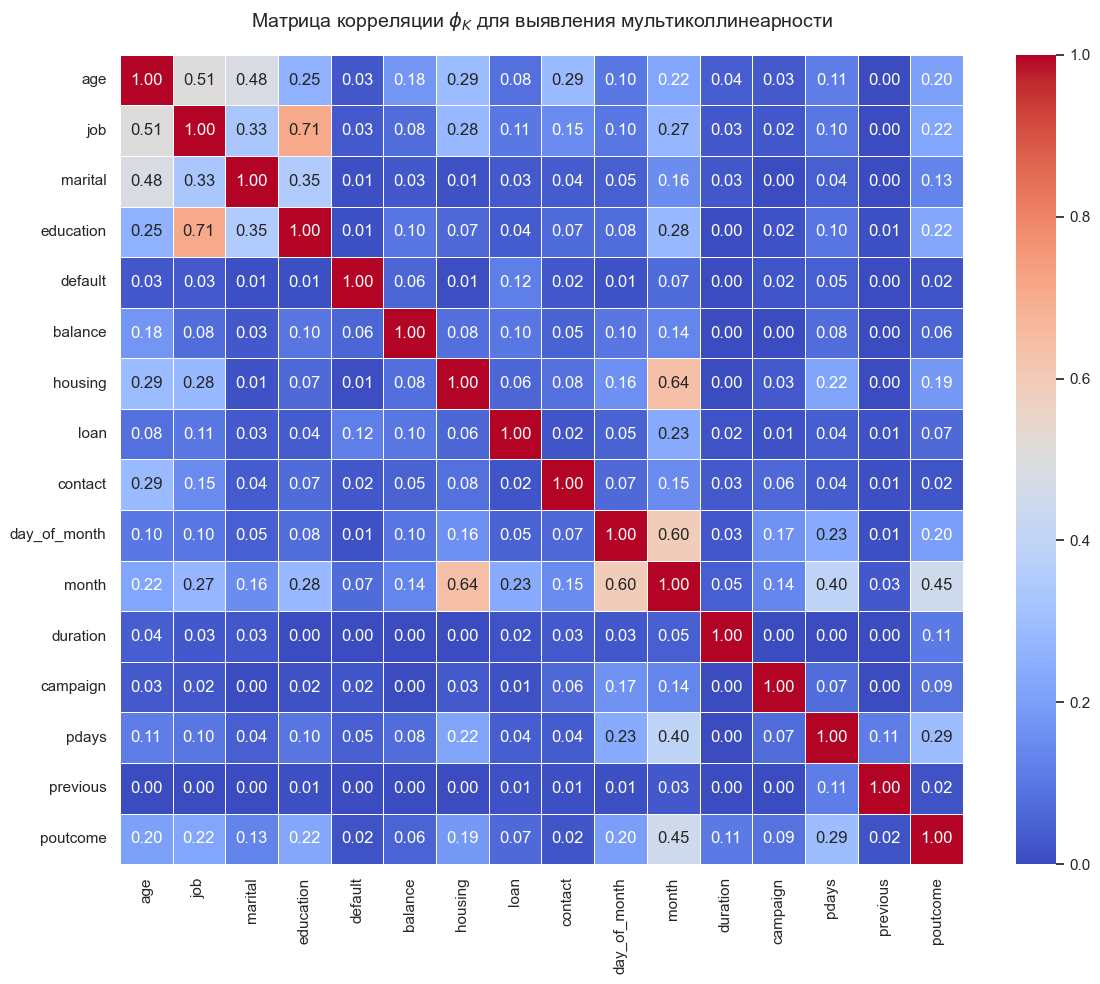


Пары признаков с уровнем мультиколлинеарности > 0.5:
  * age <---> job : coeff = 0.506
  * job <---> education : coeff = 0.708
  * housing <---> month : coeff = 0.640
  * day_of_month <---> month : coeff = 0.595


In [49]:
X_coll = df.drop(columns=['y']).copy()

# Указываем, какие колонки являются категориальными для корректного расчета phik
cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
for col in cat_cols:
    if col in X_coll.columns:
        X_coll[col] = X_coll[col].astype('category')

# 2. Рассчитываем матрицу корреляции Phi_K
phik_corr = X_coll.phik_matrix()

# 3. Визуализируем тепловую карту (Heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(phik_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1, linewidths=0.5)
plt.title("Матрица корреляции $\phi_K$ для выявления мультиколлинеарности", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# 4. Автоматический поиск сильно скоррелированных пар (порог > 0.5)
threshold = 0.5
high_corr_pairs = []

# Берём только верхний треугольник матрицы, чтобы не дублировать пары
upper_tri = phik_corr.where(np.triu(np.ones(phik_corr.shape), k=1).astype(bool))

print(f"\nПары признаков с уровнем мультиколлинеарности > {threshold}:")
for col in upper_tri.columns:
    for row in upper_tri.index:
        val = upper_tri.loc[row, col]
        if not np.isnan(val) and val > threshold:
            high_corr_pairs.append((row, col, val))
            print(f"  * {row} <---> {col} : coeff = {val:.3f}")

## Выводы
1. ***age <---> job*** : В датасете возраст сильно определяет род занятий? причина этому две полярные группы — студенты (student, молодые) и пенсионеры (retired, пожилые) — жестко привязаны к своим возрастным диапазонам.
2. ***job <---> education*** : Профессия диктует требуемый уровень образования зависимость вполне оправдана
3. ***housing <---> month*** : Похоже на поведенческий паттерн банковского маркетинга (Наример, в определенный месяц обзваниваются клиенты с ипотекой)
4. ***day_of_month <---> month*** : Предположительно - искусственная аномалия, возникшая из-за графика работы операторов банка, проведения компаний

### 4.1 Исследование признака duration

/var/folders/kr/16g6wqxx7p3b609dl_2x48sw0000gn/T/ipykernel_80678/3643906912.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  duration_stats = df.groupby('y')['duration'].agg(


СТАТИСТИЧЕСКИЙ АНАЛИЗ ПРИЗНАКА DURATION (Линейная корреляция с Y: 0.395)
     Количество  Медиана_сек  Среднее_сек  Максимум_сек  Нижний_квартиль_25
y                                                                          
no        39668        164.0        221.3          4918               164.0
yes        5255        426.0        537.7          3881               426.0
------------------------------------------------------------


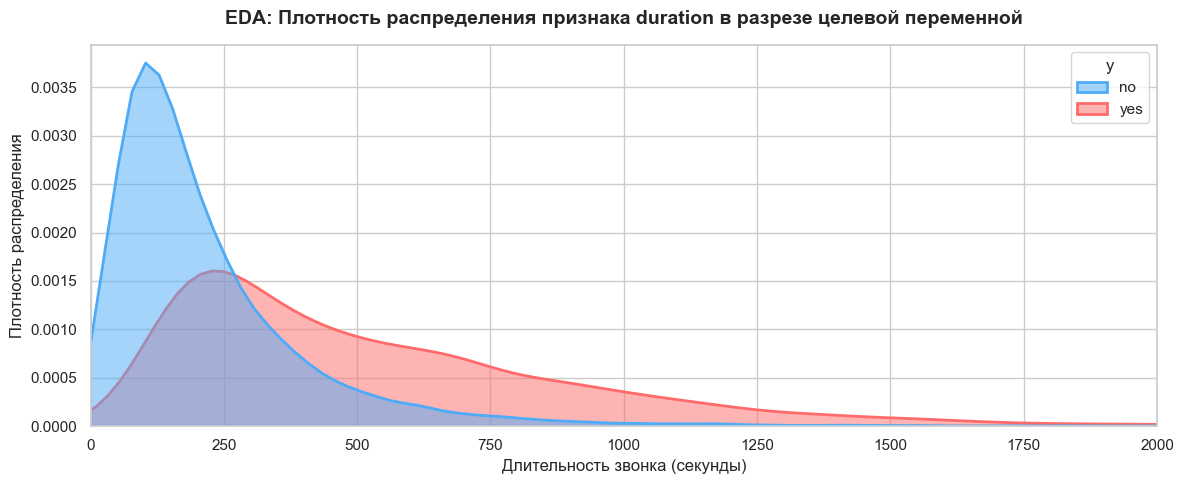

In [53]:
duration_stats = df.groupby('y')['duration'].agg(
    Количество='count',
    Медиана_сек='median',
    Среднее_сек='mean',
    Максимум_сек='max',
    Нижний_квартиль_25='quantile'
).round(1)

y_numeric = df['y'].astype(str).isin(['yes', '1']).astype(int)
corr_duration = np.corrcoef(df['duration'], y_numeric)[0, 1]

print("="*60)
print(f"СТАТИСТИЧЕСКИЙ АНАЛИЗ ПРИЗНАКА DURATION (Линейная корреляция с Y: {corr_duration:.3f})")
print("="*60)
print(duration_stats)
print("-"*60)

plt.figure(figsize=(12, 5))
sns.kdeplot(
    data=df, x='duration', hue='y', 
    fill=True, common_norm=False, 
    palette=['#4dabf7', '#ff6b6b'], alpha=0.5, linewidth=2
)
plt.title('EDA: Плотность распределения признака duration в разрезе целевой переменной', fontsize=14, pad=15, weight='bold')
plt.xlabel('Длительность звонка (секунды)', fontsize=12)
plt.ylabel('Плотность распределения', fontsize=12)
plt.xlim(0, 2000) # Ограничим хвост для наглядности основного пика
plt.tight_layout()
plt.show()

### Выводы

1. Экстремальное расхождение медиан:
   Медианная длительность разговора для успешных звонков (yes) в 4–5 раз выше, 
   чем для отказов (no). Это подтверждает, что при согласии клиент тратит время 
   на оформление анкеты, а при отказе — вешает трубку в первые минуты.

2. Характер распределения (Утечка данных):
   График наглядно демонстрирует, что при duration < 60-90 секунд вероятность 
   получить класс 'yes' стремится к нулю.

3. Признак duration является следствием (результатом взаимодействия), а не его 
   причиной и известен уже после компании.
   

### 4.2 Устранение утечки

In [54]:
if 'duration' in df.columns:
    df_model = df.drop(columns=['duration'])
    print(f"Данные успешно удалены. Размер новой таблицы для модели: {df_model.shape}")
else:
    df_model = df.copy()
    print("Признак 'duration' уже был удален ранее.")

Данные успешно удалены. Размер новой таблицы для модели: (44923, 16)


### 4.3 Анализ категориальных признаков
- base-line модель будет логистическая регрессия - кодировка всех катигориальных признаков требует понимания данных

СТАТИСТИЧЕСКИЕ ТАБЛИЦЫ РАСПРЕДЕЛЕНИЯ (Базовая конверсия банка: 11.70%)

Таблица для признака 'education':
           Количество строк  Доля в выборке (%)  Конверсия (%)  Отклонение (п.п.)
education                                                                        
tertiary              13262               30.70          15.02               3.32
secondary             23131               53.55          10.55              -1.15
primary                6800               15.74           8.65              -3.05
--------------------------------------------------------------------------------

Таблица для признака 'job':
               Количество строк  Доля в выборке (%)  Конверсия (%)  Отклонение (п.п.)
job                                                                                  
student                     938                2.09          28.68              16.98
retired                    2264                5.04          22.79              11.09
unemployed                 130

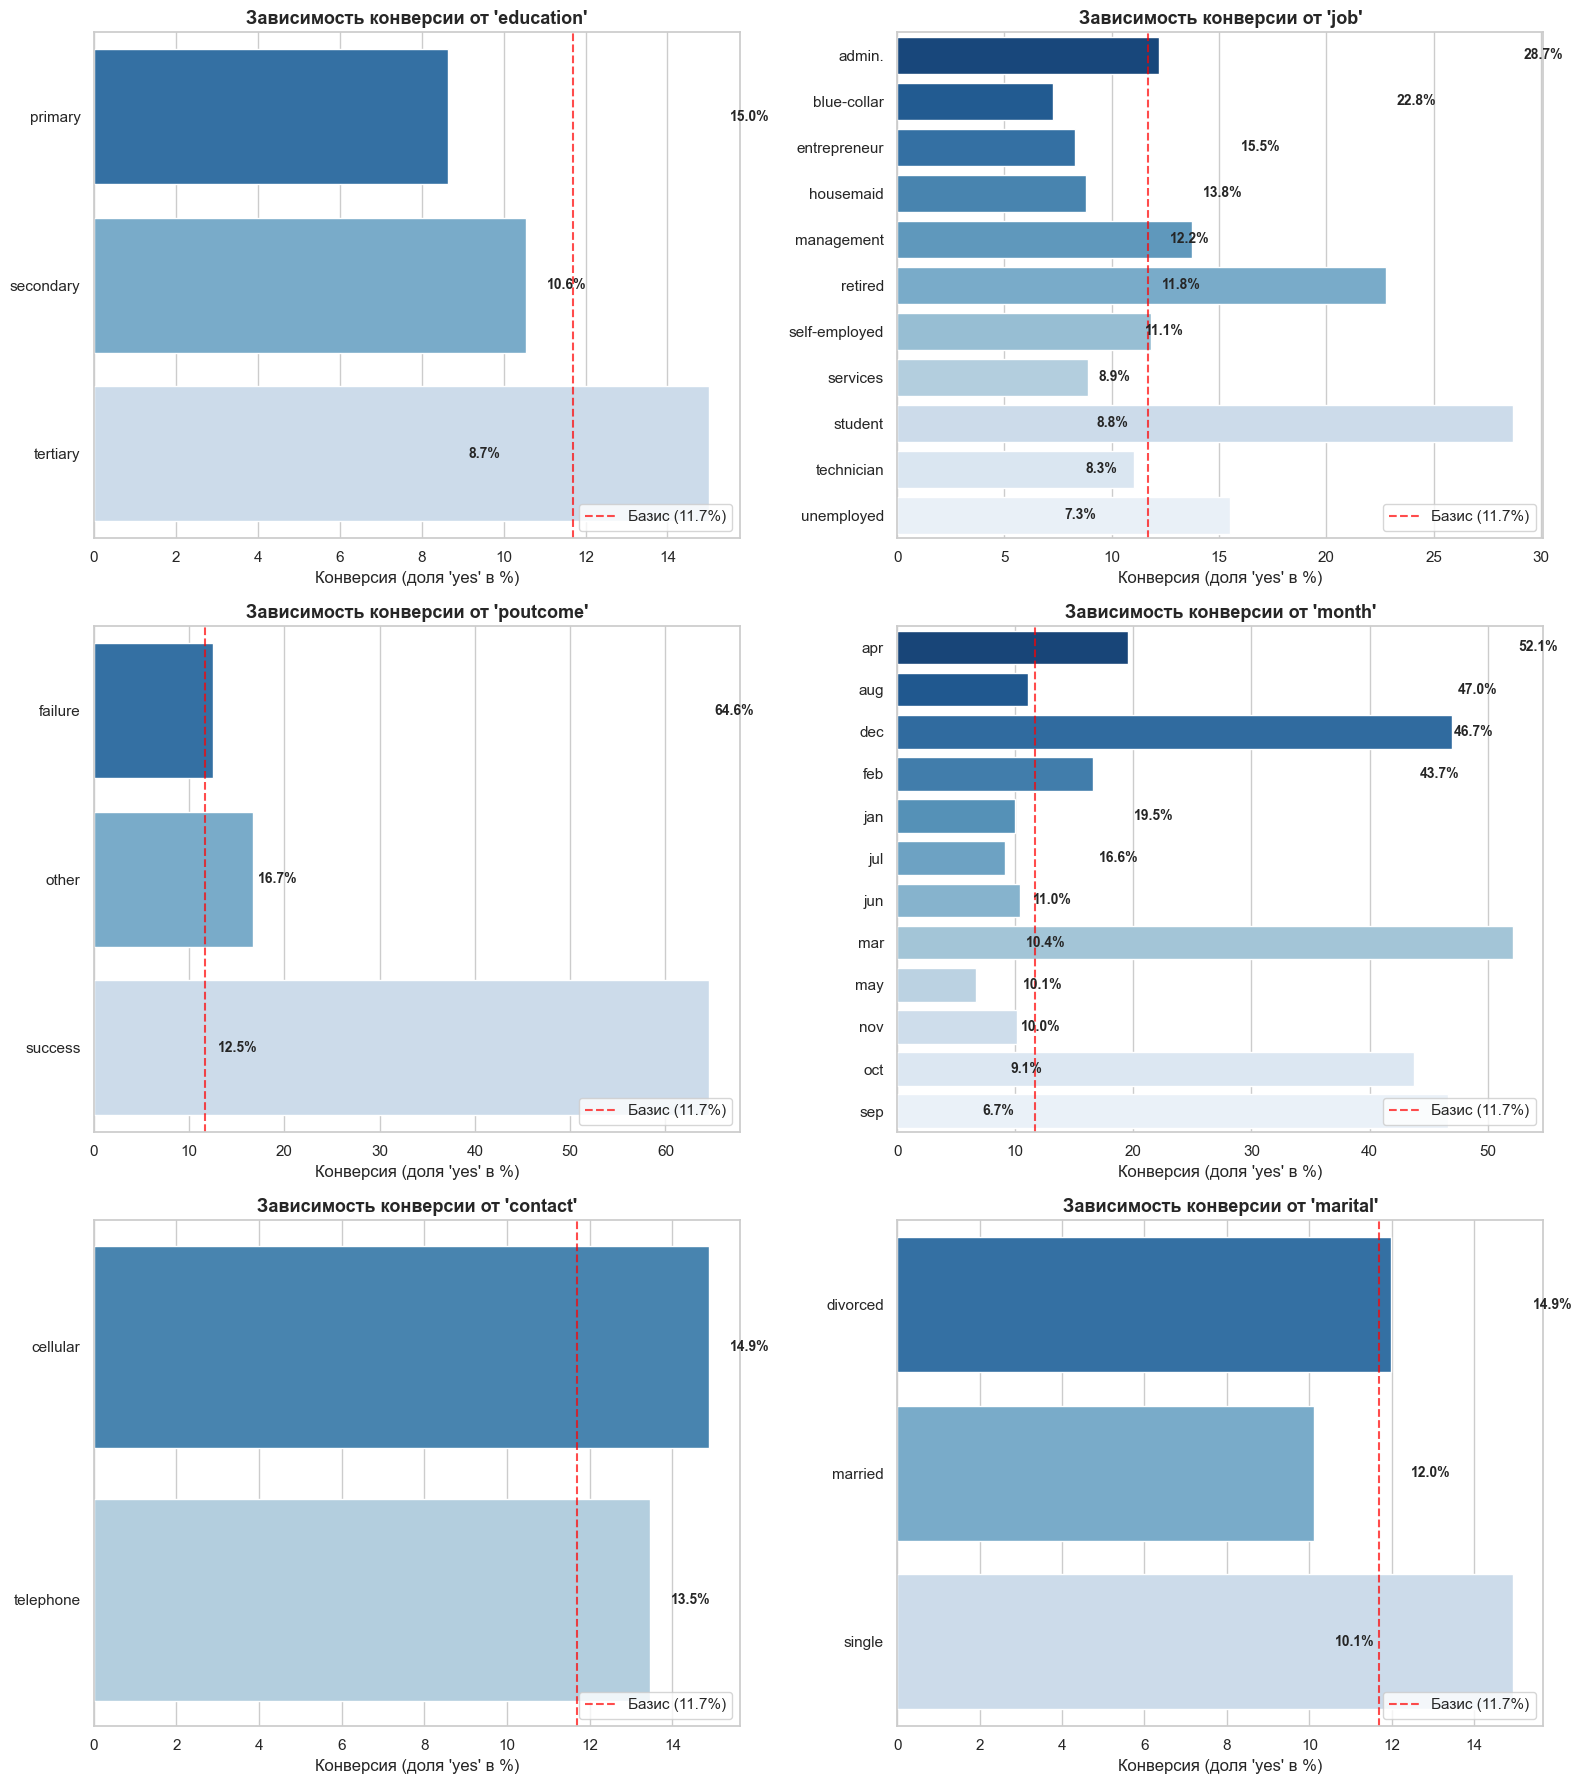

In [ ]:
target_num = (
    df_model["y"].astype(str).isin(["yes", "1"]).astype(int)
    if "y" in df_model.columns
    else df["y"]
)
base_conv = target_num.mean() * 100

cat_cols = ["education", "job", "poutcome", "month", "contact", "marital"]


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

print("=" * 80)
print(
    f"СТАТИСТИЧЕСКИЕ ТАБЛИЦЫ РАСПРЕДЕЛЕНИЯ (Базовая конверсия банка: {base_conv:.2f}%)"
)
print("=" * 80)

for i, col in enumerate(cat_cols):
    if col not in df_model.columns:
        continue


    stats_table = pd.DataFrame(
        {
            "Количество строк": df_model[col].value_counts(),
            "Доля в выборке (%)": (
                df_model[col].value_counts(normalize=True) * 100
            ).round(2),
            "Конверсия (%)": (
                target_num.groupby(df_model[col], observed=False).mean() * 100
            ).round(2),
        }
    ).sort_values(by="Конверсия (%)", ascending=False)

    stats_table["Отклонение (п.п.)"] = (
        stats_table["Конверсия (%)"] - base_conv
    ).round(2)


    print(f"\nТаблица для признака '{col}':")
    print(stats_table.to_string())
    print("-" * 80)


    sns.barplot(
        x=stats_table["Конверсия (%)"],
        y=stats_table.index,
        ax=axes[i],
        palette="Blues_r",
        hue=stats_table.index,
        legend=False,
    )
    axes[i].axvline(
        base_conv,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=f"Базис ({base_conv:.1f}%)",
    )
    axes[i].set_title(
        f"Зависимость конверсии от '{col}'", fontsize=13, weight="bold"
    )
    axes[i].set_xlabel("Конверсия (доля 'yes' в %)")
    axes[i].set_ylabel("")
    axes[i].legend(loc="lower right")

    for j, val in enumerate(stats_table["Конверсия (%)"]):
        axes[i].text(
            val + 0.5, j, f"{val:.1f}%", va="center", fontsize=10, weight="bold"
        )

plt.tight_layout()
plt.show()



| Признак | Природа признака | Самая сильная группа (конверсия, %) | Самая слабая группа (конверсия, %) | Ключевой аналитический вывод для бизнес-логики | Оптимальное кодирование |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **`education`** | Порядковый | Высшее (`tertiary` — **15.02%**) | Начальное (`primary` — **8.65%**) | Наблюдается прямая зависимость: рост уровня образования линейно повышает готовность открывать вклады. | **Ordinal Encoding** (0, 1, 2, 3) |
| **`job`** | Номинальный | Студенты (`student` — **28.68%**) | Рабочие (`blue-collar` — **7.27%**) | Максимальный отклик у групп с гибким графиком (`student`, `retired`). Самая массовая группа (`blue-collar` — 21.66% выборки) привлекается хуже всего. | **Target Encoding** |
| **`poutcome`** | Номинальный | Успех (`success` — **64.60%**) | Отказ (`failure` — **12.54%**) | Прошлый успешный контакт — мощнейший фактор лояльности. Конверсия взлетает на **+52.90 п.п.** относительно базовой. | **Target Encoding** |
| **`month`** | Номинальный | Март (`mar` — **52.11%**) | Май (`may` — **6.71%**) | Резкий сезонный дисбаланс: банк крайне эффективен весной/осенью, но тратит треть звонков (30.57%) на провальный май. | **Target Encoding** |
| **`contact`** | Номинальный | Мобильный (`cellular` — **14.89%**) | Городской (`telephone` — **13.46%**) | Мобильные номера обеспечивают более качественный контакт и более высокую конверсию, чем стационарные телефоны. | **Target Encoding** |
| **`marital`** | Номинальный | Холостые (`single` — **14.93%**) | В браке (`married` — **10.12%**) | Одинокие клиенты копят средства активнее. Семейные люди (`married` — 60.13% всей базы) показывают отклик ниже среднего по банку. | **Target Encoding** |


### 4.4 Подготовка данных для обучения модели
- base-line модель будет логистическая регрессия - кодировка всех катигориальных признаков

In [67]:
# 1. Удаляем 288 строк с пропусками в 'job' строго из df_model
df_model = df_model.dropna(subset=['job']).reset_index(drop=True)

# 2. Заполняем оставшиеся NaN в poutcome, contact и education значением 'unknown' внутри df_model
cat_cols_to_fill = ['poutcome', 'contact', 'education']
for col in cat_cols_to_fill:
    if col in df_model.columns:
        df_model[col] = df_model[col].astype(str).replace('nan', 'unknown').fillna('unknown').astype('category')

# 3. Гарантируем, что остальные категории зафиксированы как 'category'
for col in ['job', 'marital']:
    if col in df_model.columns:
        df_model[col] = df_model[col].astype('category')

# Проверяем чистоту нашей рабочей матрицы df_model
print(f"Итоговый размер df_model для обучения: {df_model.shape}")
print("Осталось пропусков в df_model:", df_model.isna().sum().sum())


Итоговый размер df_model для обучения: (44923, 16)
Осталось пропусков в df_model: 0


In [69]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44923 entries, 0 to 44922
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   age           44923 non-null  int8    
 1   job           44923 non-null  category
 2   marital       44923 non-null  category
 3   education     44923 non-null  category
 4   default       44923 non-null  category
 5   balance       44923 non-null  int32   
 6   housing       44923 non-null  category
 7   loan          44923 non-null  category
 8   contact       44923 non-null  category
 9   day_of_month  44923 non-null  int8    
 10  month         44923 non-null  category
 11  campaign      44923 non-null  int8    
 12  pdays         44923 non-null  int16   
 13  previous      44923 non-null  int16   
 14  poutcome      44923 non-null  category
 15  y             44923 non-null  category
dtypes: category(10), int16(2), int32(1), int8(3)
memory usage: 923.3 KB


In [71]:
df_model.head(15)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,no
4,35,management,married,tertiary,no,231,yes,no,unknown,5,may,1,-1,0,unknown,no
5,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,1,-1,0,unknown,no
6,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,1,-1,0,unknown,no
7,58,retired,married,primary,no,121,yes,no,unknown,5,may,1,-1,0,unknown,no
8,43,technician,single,secondary,no,593,yes,no,unknown,5,may,1,-1,0,unknown,no
9,41,admin.,divorced,secondary,no,270,yes,no,unknown,5,may,1,-1,0,unknown,no


#### Кодировка датасета

In [80]:
from sklearn.model_selection import train_test_split

# ======================================================================================
# 1. ВЫДЕЛЕНИЕ ПРИЗНАКОВ И СТРАТИФИЦИРОВАННОЕ РАЗДЕЛЕНИЕ
# ======================================================================================

# Выделяем признаки (X) и таргет (y)
X = df_model.drop(columns=["y"], errors="ignore").copy()
y = df_model["y"].astype(str).isin(["yes", "1"]).astype(int)

# Разделяем на train и test (80/20) со строгим сохранением дисбаланса классов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Сбрасываем индексы 
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

# ======================================================================================
# 2. ПОЛНЫЙ ЦИКЛ КОДИРОВАНИЯ ПРИЗНАКОВ
# ======================================================================================

# --- А. Бинарное кодирование (default, housing, loan) -> 1 и 0 ---
bin_cols = ["default", "housing", "loan"]
for col in bin_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype(str).isin(["yes"]).astype("int8")
        X_test[col] = X_test[col].astype(str).isin(["yes"]).astype("int8")

# --- Б. Порядковое кодирование (education) -> 0, 1, 2, 3 ---
# Снимаем ограничения типа 'category', маппим ранги, 'unknown' выносим в базис (0)
if "education" in X_train.columns:
    edu_map = {"unknown": 0, "primary": 1, "secondary": 2, "tertiary": 3}
    X_train["education"] = X_train["education"].astype(str).map(edu_map).astype("int8")
    X_test["education"] = X_test["education"].astype(str).map(edu_map).astype("int8")

# --- В. Кодирование частотой (job, marital, contact, month, poutcome) ---
# Считаем частоты строго по обучающей выборке X_train с защитой от CategoricalDtypeError
freq_cols = ["job", "marital", "contact", "month", "poutcome"]
for col in freq_cols:
    if col in X_train.columns:
        # Переводим в строку, чтобы pandas позволил записать числовые частоты и нули
        X_train[col] = X_train[col].astype(str)
        X_test[col] = X_test[col].astype(str)

        # Рассчитываем доли категорий строго на TRAIN выборке
        freq_map = X_train[col].value_counts(normalize=True).to_dict()

        # Заменяем категории частотами. Если в тесте будет неизвестный класс — пишем 0
        X_train[col] = X_train[col].map(freq_map).fillna(0).astype("float32")
        X_test[col] = X_test[col].map(freq_map).fillna(0).astype("float32")

# ======================================================================================
# 3. ПРОВЕРКА СОХРАНЕНИЯ ДИСБАЛАНСА И СТРУКТУРЫ ДАННЫХ
# ======================================================================================
print(f"Размер признаков обучения X_train: {X_train.shape}")
print(f"Размер признаков теста    X_test:  {X_test.shape}")
print("-" * 60)
print(f"Доля целевого класса 'yes' в исходном df_model: {y.mean():.2%}")
print(f"Доля целевого класса 'yes' в выборке Train:     {y_train.mean():.2%}")
print(f"Доля целевого класса 'yes' в выборке Test:      {y_test.mean():.2%}")
print("-" * 60)
print("Все категориальные признаки успешно переведены в числовые форматы.")


Размер признаков обучения X_train: (35938, 15)
Размер признаков теста    X_test:  (8985, 15)
------------------------------------------------------------
Доля целевого класса 'yes' в исходном df_model: 11.70%
Доля целевого класса 'yes' в выборке Train:     11.70%
Доля целевого класса 'yes' в выборке Test:      11.70%
------------------------------------------------------------
Все категориальные признаки успешно переведены в числовые форматы.


## 5. Построение baseline-модели

In [76]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [77]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

# обучим модель лог.регрессии
lr_model.fit(X_train, y_train)

# воспользуемся уже обученной моделью, чтобы сделать прогнозы
lr_predictions = lr_model.predict(X_test)

In [78]:
from sklearn.metrics import classification_report
print(classification_report(y_test, lr_predictions))

              precision    recall  f1-score   support

           0       0.89      1.00      0.94      7934
           1       0.56      0.02      0.04      1051

    accuracy                           0.88      8985
   macro avg       0.72      0.51      0.49      8985
weighted avg       0.85      0.88      0.83      8985

